In [77]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# **3.2. Opción B: Modelo presa–depredador de Lotka–Volterra (conejos y zorros)**

## Implementemos el método RK4 para resolver sistemas de EDO's

In [78]:
def rk4_sistemas(t,f,y0):
  n = len(t)  ## Nodos temporales
  m = len(y0)   ## Cantidad de ecuaciones, entendiendo a y como los PVI
  Y = np.zeros((m,n))  ## Creamos la matriz donde almacenamos las soluciones
  Y[:,0] = y0    ## Inicializamos la matriz según y0
  h = t[1] - t[0]   ## tamaño de paso equiespaciado

  for i in range(n-1):
    ti = t[i]
    yi = Y[:,i]
    ## ahora definamos las pendientes
    k1 = h * f(ti, yi)
    k2 = h* f(ti+0.5*h, yi+0.5*k1)
    k3 = h* f(ti + 0.5*h, yi+0.5*k2)
    k4 = h*f(ti+h, yi+k3)

    Y[:,i+1] = yi + (1/6)*(k1 + 2*k2 + 2*k3 + k4)
  return Y

In [ ]:
# Parámetros del modelo
alpha = 0.5     # natalidad conejos
beta  = 0.002   # efectividad de depredación
gamma = 0.3     # mortalidad zorros
delta = 0.001   # reproducción zorros 

    

def f_lv(t, U):
    """
    x(t): conejos (presas)
    y(t): zorros  (depredadores)
    """
    x, y = U
    dxdt = alpha*x - beta*x*y
    dydt = delta*x*y - gamma*y
    return np.asarray([dxdt, dydt])

In [80]:
# Condiciones iniciales
x0 = 40   # conejos iniciales
y0 = 40    # zorros iniciales
y0_vec = [x0, y0]

# Intervalo de tiempo y paso
a, b = 0, 80    # tiempo
h = 0.1
t = np.arange(a, b + h, h)   

Ejecución del método

In [81]:
Y = rk4_sistemas(t, f_lv, y0_vec)
x_aprox, y_aprox = Y      # x(t) ≈ conejos, y(t) ≈ zorros

### Gráficas: poblaciones vs tiempo

In [82]:
##### Cambiar el estilo de las graficas en general
plt.style.use('bmh') #seaborn-v0_8-darkgrid
plt.rcParams.update({
    "font.size": 12,            # tamaño base
    "font.family": "serif",     # tipo de letra global
    "axes.titleweight": "bold", # titulos en negrita
})

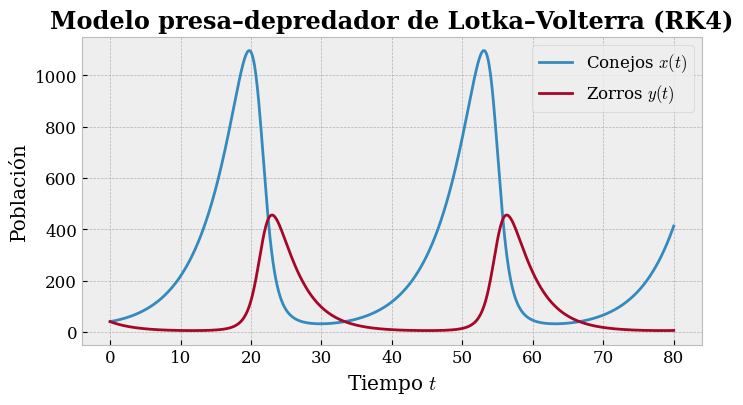

In [83]:
plt.figure(figsize=(8, 4))
plt.plot(t, x_aprox, label='Conejos $x(t)$')
plt.plot(t, y_aprox, label='Zorros $y(t)$')
plt.xlabel('Tiempo $t$')
plt.ylabel('Población')
plt.title('Modelo presa–depredador de Lotka–Volterra (RK4)')
plt.grid(True)
plt.legend()
plt.show()


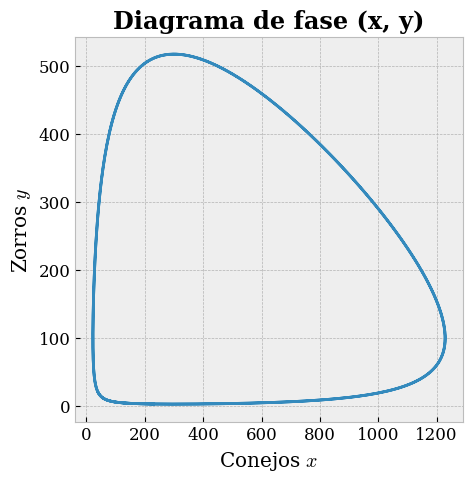

In [84]:
# Condiciones iniciales
x0 = 40   # conejos iniciales
y0 = 20    # zorros iniciales
y0_vec = [x0, y0]

# Intervalo de tiempo y paso
a, b = 0, 80    # tiempo
h = 0.1
t = np.arange(a, b + h, h)   

Y = rk4_sistemas(t, f_lv, y0_vec)
x_aprox, y_aprox = Y      # x(t) ≈ conejos, y(t) ≈ zorros


plt.figure(figsize=(5, 5))
plt.plot(x_aprox, y_aprox)
plt.xlabel('Conejos $x$')
plt.ylabel('Zorros $y$')
plt.title('Diagrama de fase (x, y)')
plt.grid(True)
plt.show()


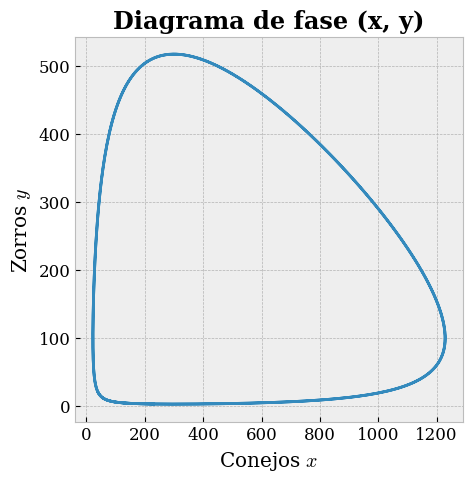

In [85]:
plt.figure(figsize=(5, 5))
plt.plot(x_aprox, y_aprox)
plt.xlabel('Conejos $x$')
plt.ylabel('Zorros $y$')
plt.title('Diagrama de fase (x, y)')
plt.grid(True)
plt.show()


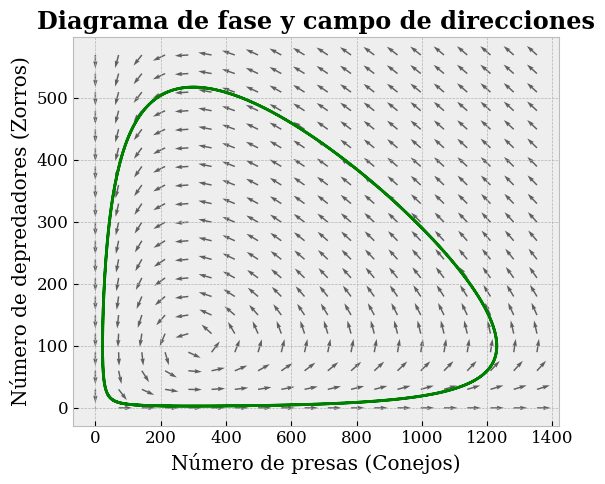

In [86]:
# Rango donde para ver flechas
x_vals = np.linspace(0, 1.1 * x_aprox.max(), 20)
y_vals = np.linspace(0, 1.1 * y_aprox.max(), 20)

X, Y = np.meshgrid(x_vals, y_vals)

# Evaluamos el sistema en cada punto (X, Y)
U = alpha*X - beta*X*Y          # dx/dt
V = delta*X*Y - gamma*Y         # dy/dt

# Normalizamos para que todas las flechas tengan tamaño parecido
N = np.sqrt(U**2 + V**2)
N[N == 0] = 1                   # evitar división por cero
U /= N
V /= N

plt.figure(figsize=(6, 5))

# Campo de direcciones
plt.quiver(X, Y, U, V, angles="xy", alpha=0.6)

# Órbita 
plt.plot(x_aprox, y_aprox, color="green", linewidth=2)

plt.xlabel('Número de presas (Conejos)')
plt.ylabel('Número de depredadores (Zorros)')
plt.title('Diagrama de fase y campo de direcciones')
plt.grid(True)
plt.tight_layout()
plt.show()


# **4.1. Opción 1: Horas de estudio vs. puntaje de examen**

## Regresión Lineal

**Contexto.** Este conjunto de datos examina la relación entre el tiempo que un estudiante
dedica al estudio y el resultado obtenido en un examen. Se trata de un ejemplo clásico en
modelos educativos: ¿más horas de estudio implican mejor desempeño?, ¿cuánto mejora, en
promedio, un puntaje cuando se estudia una hora adicional? Los datos permiten observar
una tendencia positiva clara, ideal para una regresión simple.

In [87]:
def ajuste_minimos_cuadrados(x, y):
    """
    Ajusta una recta y ≈ a + b x por mínimos cuadrados
    usando fórmulas escalares/vectoriales (sin matrices explícitas).

    Parámetros
    ----------
    x, y : np.ndarray de shape (n,)
        Datos de entrada.

    Retorna
    -------
    a, b : floats
        Parámetros del ajuste.
    mse : float
        Error cuadrático medio del ajuste.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # TODO:
    # 1. Calcular las medias x_bar y y_bar.
    # 2. Calcular el numerador y el denominador de b:
    #       num = sum( (x - x_bar)*(y - y_bar) )
    #       den = sum( (x - x_bar)**2 )
    #    y luego b = num / den.
    # 3. Calcular a = y_bar - b * x_bar.
    # 4. Calcular las predicciones y_pred = a + b*x y el MSE:
    #       mse = promedio de (y - y_pred)**2.
    x_bar = np.mean(x)
    y_bar = np.mean(y)


    num = np.sum((x - x_bar)*(y - y_bar))
    den = np.sum((x - x_bar)**2)
    b = num / den

    a = y_bar - b * x_bar

    y_pred =  a+b*x
    mse = np.mean((y - y_pred)**2)


    return a, b, mse

In [88]:
def r_2(x, y):
    x = np.array(x)    ### Se convierte a arreglo numpy, si tiene sentido x**2
    a_0, a_1, mse =  ajuste_minimos_cuadrados(x, y)
    w = a_0 + a_1 * x
    y_mean = np.mean(y)
    w_ = (w - y_mean)**2
    y_ = (y - y_mean)**2
    num = np.sum(w_)
    den = np.sum(y_)
    return num / den

In [89]:
# Cambia el nombre por el archivo exacto que subiste a Colab
filename = "C:\\Users\\Luis\\Desktop\\MetodosNumericos\\Final\\student_scores.csv"

# Leer CSV con pandas (solo para exploración)
df = pd.read_csv(filename)

print("=== Primeras filas del dataset ===")
display(df.head())

# Convertimos a vectores numpy para nuestro ajuste por mínimos cuadrados
x_data = df["Hours"].values
y_data = df["Scores"].values

print("\n=== Formas de los vectores x e y ===")
print("x:", x_data.shape)
print("y:", y_data.shape)

=== Primeras filas del dataset ===


,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30



=== Formas de los vectores x e y ===
x: (11,)
y: (11,)


a estimado = -0.4992
b estimado = 9.7832
Error cuadrático medio (MSE) = 26.0844
r2 = 0.9625


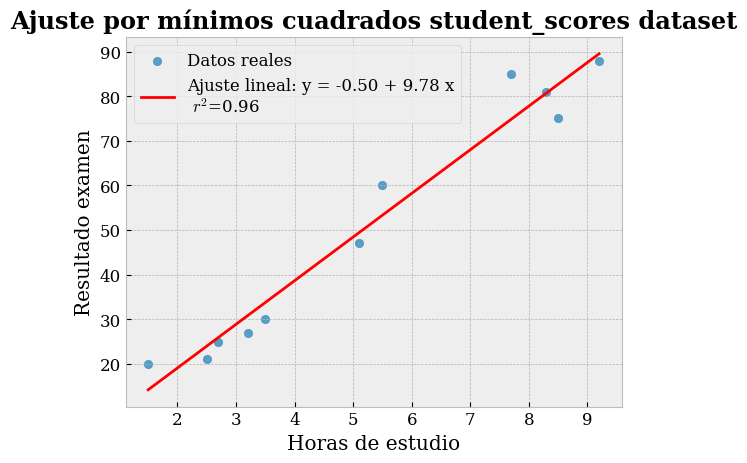

In [90]:
# Ajuste del modelo
a_est, b_est, mse_est = ajuste_minimos_cuadrados(x_data, y_data)
r2 = r_2(x_data, y_data)
print(f"a estimado = {a_est:.4f}")
print(f"b estimado = {b_est:.4f}")
print(f"Error cuadrático medio (MSE) = {mse_est:.4f}")
print(f"r2 = {r2:.4f}")
# Gráfico
x_plot = np.linspace(x_data.min(), x_data.max(), 200)
y_fit = a_est + b_est * x_plot

plt.scatter(x_data, y_data, label="Datos reales", alpha=0.8)
plt.plot(x_plot, y_fit, color="red", label=f"Ajuste lineal: y = {a_est:.2f} + {b_est:.2f} x\n $r^2$={r2:.2f}")
plt.xlabel("Horas de estudio")
plt.ylabel("Resultado examen")
plt.title("Ajuste por mínimos cuadrados student_scores dataset")
plt.legend()
plt.grid(True)
plt.show()